# Explainable ECG classification

**Tanvi Bandebuche and Maheen Meshram**  
Computer Science and Engineering, Symbiosis Institute Of Technology, Nagpur, India

We compare lightweight models that predict five diagnostic labels from a 12-lead ECG.
One ECG can contain several labels, so this is a multi-label classification problem.

This notebook explains the dataset, model architecture, training protocol, and measured results.
The default cells recalculate the saved scores without the raw waveform dataset.
The last two sections let you run a real ECG example or start a fresh experiment.
Both sections are off by default.

Run the cells in order. Read each short explanation before the next cell.

## 1. Open the project

In Jupyter, open this notebook from the project folder.
In Colab, this cell downloads the public repository.
The source files, checkpoints, and prediction files stay together.

In [1]:
from pathlib import Path
import importlib.util
import subprocess
import sys

REPOSITORY = "https://github.com/Tanvib24/explainable-ecg-classification.git"
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent]
             if (p / "configs/protocol.json").is_file()), None)
if ROOT is None:
    if not Path("/content").is_dir():
        raise RuntimeError("Open the notebook from the cloned project folder.")
    ROOT = Path("/content/explainable-ecg-classification")
    if not ROOT.exists():
        subprocess.run(["git", "clone", REPOSITORY, str(ROOT)], check=True)
assert (ROOT / "ecg_project/models.py").is_file(), "Project source is missing."
RESULTS = ROOT / "results"
sys.path.insert(0, str(ROOT))
print("The project files are ready.")

The project files are ready.


## 2. Load the libraries

This cell installs missing libraries only.
The original package versions are in requirements-lock.txt.
A new Jupyter installation can use requirements-notebook.txt.
Different environments can produce small numeric differences.

In [2]:
libraries = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn",
             "matplotlib": "matplotlib", "torch": "torch", "wfdb": "wfdb",
             "requests": "requests", "joblib": "joblib"}
missing = [package for module, package in libraries.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)

import hashlib
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from IPython.display import display, Image
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve
from ecg_project.models import build_model, parameter_count

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})
pd.set_option("display.precision", 4)
display(pd.Series({"Python": sys.version.split()[0], "NumPy": np.__version__,
                   "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                   "PyTorch": torch.__version__}, name="Notebook environment").to_frame())
config = json.loads((ROOT / "configs/protocol.json").read_text())
CLASSES = config["classes"]

,Notebook environment
Python,3.12.14
NumPy,2.5.4
pandas,3.1.0
scikit-learn,1.9.1
PyTorch,2.14.1+cpu


## 3. Understand the dataset split

PTB-XL version 1.0.3 contains 21,799 ECG recordings.
We exclude 411 recordings without a mapped diagnostic category.
The final cohort contains 21,388 recordings.

We keep the official folds: 1–8 for training, 9 for validation, and 10 for testing.
The original data checks found no patient overlap or exact waveform duplicates between these groups.
This cell reads the saved audit. It does not repeat the raw-data checks.

NORM means normal ECG. MI means myocardial infarction. STTC means ST/T change.
CD means conduction disturbance. HYP means hypertrophy.
Label counts overlap because one recording can contain several labels.

Source: [PTB-XL version 1.0.3](https://doi.org/10.13026/kfzx-aw45).

,ECGs,Patients
train,17084,14823
validation,2146,1917
test,2158,1877


,NORM,MI,STTC,CD,HYP
train,7596,4379,4186,3907,2119
validation,955,540,528,495,268
test,963,550,521,496,262


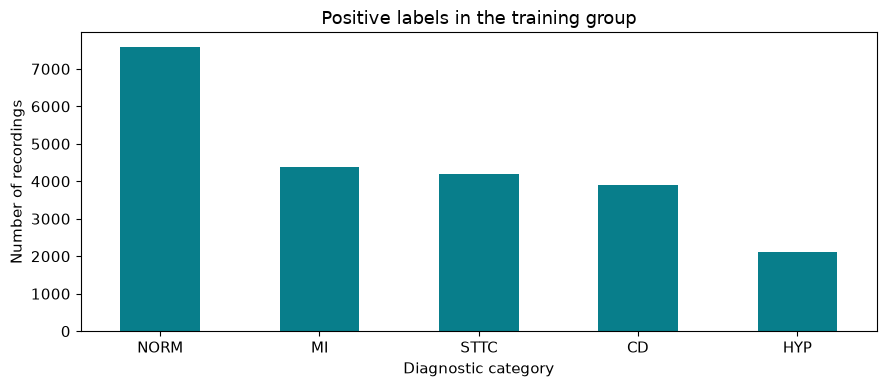

In [3]:
audit = json.loads((RESULTS / "data-audit.json").read_text())
splits = pd.DataFrame({name: {"ECGs": values["recordings"], "Patients": values["patients"]}
                       for name, values in audit["splits"].items()}).T
display(splits)
assert splits["ECGs"].sum() == audit["eligible_records"] == 21388
assert audit["patient_disjoint"] and audit["cross_partition_exact_duplicates"] == 0
labels = pd.DataFrame({name: values["positive_labels"]
                       for name, values in audit["splits"].items()}).T
display(labels)
labels.loc["train"].plot.bar(color="#087E8B", rot=0)
plt.title("Positive labels in the training group")
plt.ylabel("Number of recordings")
plt.xlabel("Diagnostic category")
plt.tight_layout()
plt.show()

## 4. Read the normalization values

Each input contains 12 leads and 1,000 samples at 100 Hz.
Each lead has a separate mean and standard deviation from training data only.
The same values transform validation and test data.

For each lead, z = (x − mean) / (standard deviation + 0.000001).
The positive class weight equals the training negative count divided by the training positive count.

In [4]:
with np.load(RESULTS / "normalization.npz", allow_pickle=False) as saved:
    train_mean = saved["mean"].copy()
    train_std = saved["std"].copy()
    class_weights = saved["pos_weight"].copy()
leads = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
display(pd.DataFrame({"Lead": leads, "Training mean": train_mean,
                      "Training standard deviation": train_std}))
display(pd.Series(class_weights, index=CLASSES, name="Positive class weight").to_frame())

,Lead,Training mean,Training standard deviation
0,I,-0.0017,0.1600
1,II,-0.0015,0.1592
2,III,0.0002,0.1600
3,aVR,0.0016,0.1381
4,aVL,-0.0009,0.1388
5,aVF,-0.0006,0.1380
6,V1,0.0002,0.2343
7,V2,-0.0010,0.3342
8,V3,-0.0016,0.3285
9,V4,-0.0014,0.2928


,Positive class weight
NORM,1.2491
MI,2.9013
STTC,3.0812
CD,3.3727
HYP,7.0623


## 5. Inspect the models

The compact CNN has three convolution blocks with 64, 128, and 192 output channels.
Their kernel sizes are 15, 9, and 5. Each block uses stride 2, batch normalization, and ReLU.
Global average pooling feeds a dense layer with 64 units and five output logits.
A sigmoid converts each logit to a separate category score.
These scores do not sum to one. They are not calibrated clinical probabilities.

The residual and inception models use smaller CPU configurations.
They compare architecture families rather than reproduce published checkpoints.
The model definitions are in ecg_project/models.py.

In [5]:
torch.set_num_threads(config["torch_threads"])
model_rows = []
for name in config["models"]:
    model = build_model(name, config["dropout"], config["model_profile"]).eval()
    with torch.inference_mode():
        output = model(torch.zeros(1, 12, 1000))
    assert output.shape == (1, 5) and torch.isfinite(output).all()
    model_rows.append({"Model": name, "Parameters": parameter_count(model),
                       "Output shape": str(tuple(output.shape))})
display(pd.DataFrame(model_rows).set_index("Model"))
print(build_model("compact_cnn", config["dropout"], config["model_profile"]))
print("The zero input checks tensor shapes only.")

,Parameters,Output shape
Model,,
compact_cnn,221573,"(1, 5)"
resnet1d,244005,"(1, 5)"
inception_time,115729,"(1, 5)"


CompactCNN(
  (features): Sequential(
    (0): ConvBlock(
      (0): Conv1d(12, 64, kernel_size=(15,), stride=(2,), padding=(7,), bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): ConvBlock(
      (0): Conv1d(64, 128, kernel_size=(9,), stride=(2,), padding=(4,), bias=False)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (2): ConvBlock(
      (0): Conv1d(128, 192, kernel_size=(5,), stride=(2,), padding=(2,), bias=False)
      (1): BatchNorm1d(192, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
    )
    (3): AdaptiveAvgPool1d(output_size=1)
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (head): Sequential(
    (0): Linear(in_features=192, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_feature

## 6. Read the training protocol

Each neural configuration uses seeds 42, 123, and 2026.
Three model families and the unweighted CNN comparison produce 12 neural runs.
A logistic baseline uses 96 waveform summary features.

The weighted models use binary cross entropy with training class weights.
The unweighted CNN uses the same architecture and configuration, with all positive weights equal to one.
Validation macro AUROC selects the checkpoints. Validation F1 selects the category thresholds.
We freeze both before test evaluation.

,Value
optimizer,AdamW
learning_rate,0.001
weight_decay,0.0001
batch_size,64
dropout,0.2
max_epochs,25
early_stopping_patience,5
seeds,"[42, 123, 2026]"
device,cpu


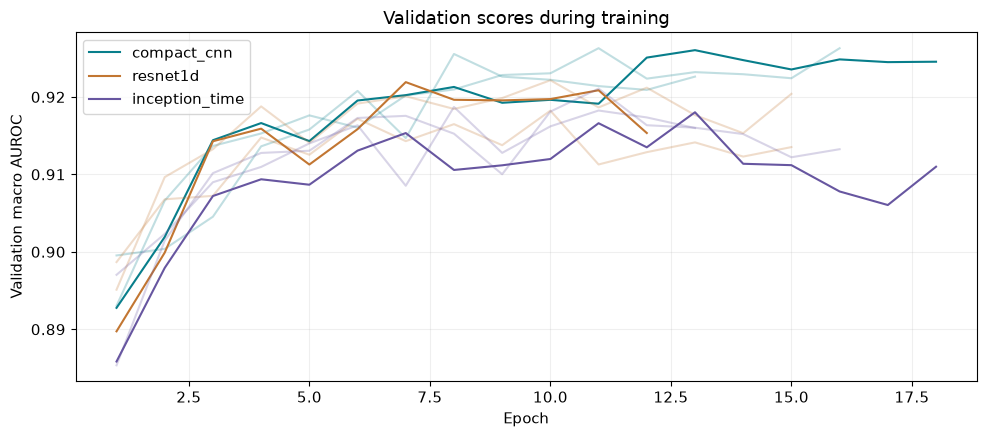

In [6]:
settings = {key: config[key] for key in ["optimizer", "learning_rate", "weight_decay",
            "batch_size", "dropout", "max_epochs", "early_stopping_patience", "seeds", "device"]}
display(pd.Series(settings, name="Value").to_frame())
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = {"compact_cnn": "#087E8B", "resnet1d": "#C27632", "inception_time": "#6756A0"}
for name in config["models"]:
    for seed in config["seeds"]:
        history = pd.read_csv(RESULTS / "runs" / f"{name}_seed{seed}" / "history.csv")
        ax.plot(history["epoch"], history["validation_macro_auroc"], color=colors[name],
                alpha=1 if seed == 42 else 0.25, label=name if seed == 42 else None)
ax.set(xlabel="Epoch", ylabel="Validation macro AUROC", title="Validation scores during training")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Check the saved experiment

This cell checks the source files, checkpoints, and recorded selection times.
It reads Windows paths correctly on Linux and Colab.
The bundle check covers the recorded source, configuration, and result files.
It excludes this editable notebook and the submission documents.

A hash detects file changes. It does not prove that the experiment design is correct.
The full raw-data check is in scripts/verify_evidence.py.
That check also compares the saved labels and ECG identifiers with the prepared cohort.

In [7]:
def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

bundle = json.loads((RESULTS / 'bundle-manifest.json').read_text())
for name, expected in bundle['included_files'].items():
    if not name.startswith(('ecg_project/', 'configs/', 'results/')):
        continue
    path = ROOT / name.replace(chr(92), "/")
    assert path.is_file(), f'Missing: {name}'
    assert digest(path) == expected['sha256'], f'File changed: {name}'
frozen = json.loads((RESULTS / 'frozen-selection.json').read_text())
manifest = json.loads((RESULTS / 'training-manifest.json').read_text())
access = json.loads((RESULTS / 'test-access-log.json').read_text())
complete = json.loads((RESULTS / 'test-evaluation-complete.json').read_text())
assert frozen['source_fingerprints'] == manifest['source_fingerprints']
for name, expected in frozen['source_fingerprints'].items():
    assert digest(ROOT / name.replace(chr(92), "/")) == expected, f'Locked source changed: {name}'
assert frozen['test_performance_accessed'] is False
assert frozen['frozen_utc'] <= access['first_test_inference_utc'] <= complete['completed_utc']
assert access['frozen_selection_sha256'] == complete['frozen_selection_sha256'] == digest(RESULTS / 'frozen-selection.json')
assert complete['all_runs_csv_sha256'] == digest(RESULTS / 'all-runs.csv')
assert len(frozen['runs']) == 12
print('The recorded source, checkpoints, and selection order pass the checks.')

The recorded source, checkpoints, and selection order pass the checks.

## 8. Recalculate the test scores

The prediction files contain true labels, scores, thresholds, ECG identifiers, and patient identifiers.
This cell recalculates AUROC, average precision, and F1 for all 12 neural runs.
Macro metrics give each category equal weight. F1 uses the frozen validation thresholds.
A tolerance of 1e-8 allows small numeric differences between library versions.

In [8]:
rows = []
reference = None
for run in frozen['runs']:
    folder = RESULTS / 'runs' / run['tag']
    measured = json.loads((folder / 'test-results.json').read_text())
    assert digest(folder / 'best.pt') == run['checkpoint_sha256']
    assert digest(folder / 'test-predictions.npz') == measured['test_predictions_sha256']
    with np.load(folder / 'test-predictions.npz', allow_pickle=False) as saved:
        truth = saved['y_true']
        probability = saved['y_probability']
        thresholds = saved['thresholds']
        ids = saved['ecg_id']
        patients = saved['patient_id']
    assert truth.shape == probability.shape == (2158, 5)
    assert len(np.unique(patients)) == 1877
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    np.testing.assert_allclose(thresholds, run['thresholds'])
    if reference is None:
        reference = (truth.copy(), ids.copy(), patients.copy())
    for actual, expected in zip((truth, ids, patients), reference):
        np.testing.assert_array_equal(actual, expected)
    binary = probability >= thresholds
    scores = {
        'macro_auroc': roc_auc_score(truth, probability, average='macro'),
        'macro_average_precision': average_precision_score(truth, probability, average='macro'),
        'macro_f1': f1_score(truth, binary, average='macro', zero_division=0),
        'micro_f1': f1_score(truth, binary, average='micro', zero_division=0),
    }
    for name, value in scores.items():
        np.testing.assert_allclose(value, measured['tuned_threshold_metrics'][name], rtol=0, atol=1e-8)
    rows.append({'run': run['tag'], 'model': run['model'], 'weighted': run['weighted'],
                 'seed': run['seed'], **scores})
recomputed = pd.DataFrame(rows)
display(recomputed)
print('PASS: all 12 neural runs match the saved test scores.')

,run,model,weighted,seed,macro_auroc,macro_average_precision,macro_f1,micro_f1
0,compact_cnn_seed42,compact_cnn,True,42,0.9178,0.7984,0.7360,0.7704
1,compact_cnn_seed123,compact_cnn,True,123,0.9200,0.8002,0.7349,0.7663
2,compact_cnn_seed2026,compact_cnn,True,2026,0.9208,0.8069,0.7397,0.7692
3,resnet1d_seed42,resnet1d,True,42,0.9150,0.7912,0.7212,0.7540
4,resnet1d_seed123,resnet1d,True,123,0.9151,0.7966,0.7241,0.7567
5,resnet1d_seed2026,resnet1d,True,2026,0.9120,0.7926,0.7198,0.7506
6,inception_time_seed42,inception_time,True,42,0.9145,0.7938,0.7286,0.7587
7,inception_time_seed123,inception_time,True,123,0.9143,0.7934,0.7240,0.7596
8,inception_time_seed2026,inception_time,True,2026,0.9137,0.7975,0.7249,0.7576
9,compact_cnn_seed42_unweighted,compact_cnn,False,42,0.9164,0.8023,0.7330,0.7658


PASS: all 12 neural runs match the saved test scores.


## 9. Compare the models

The next cell checks the mean and sample standard deviation across the three seeds.
It also recalculates the logistic baseline scores.

In [9]:
aggregate = json.loads((RESULTS / 'aggregate-results.json').read_text())
for (model, weighted), group in recomputed.groupby(['model', 'weighted']):
    key = model + ('' if weighted else '_unweighted')
    assert len(group) == 3
    for metric in ['macro_auroc', 'macro_average_precision', 'macro_f1', 'micro_f1']:
        np.testing.assert_allclose(group[metric].mean(), aggregate[key]['metrics'][metric]['mean'], rtol=0, atol=1e-8)
        np.testing.assert_allclose(group[metric].std(ddof=1), aggregate[key]['metrics'][metric]['sample_std'], rtol=0, atol=1e-8)
display(recomputed.groupby(['model', 'weighted'])[['macro_auroc', 'macro_average_precision', 'macro_f1']].agg(['mean', 'std']))
with np.load(RESULTS / 'logistic-test-predictions.npz', allow_pickle=False) as saved:
    truth, probability, thresholds = saved['y_true'], saved['y_probability'], saved['thresholds']
np.testing.assert_array_equal(truth, reference[0])
baseline = {
    'macro_auroc': roc_auc_score(truth, probability, average='macro'),
    'macro_average_precision': average_precision_score(truth, probability, average='macro'),
    'macro_f1': f1_score(truth, probability >= thresholds, average='macro', zero_division=0),
}
recorded = json.loads((RESULTS / 'logistic-test-results.json').read_text())['tuned_threshold_metrics']
for name, value in baseline.items():
    np.testing.assert_allclose(value, recorded[name], rtol=0, atol=1e-8)
display(pd.DataFrame([baseline], index=['Logistic baseline']))
print('PASS: seed averages, sample standard deviations, and logistic baseline scores.')

macro_auroc         macro_average_precision          \
                               mean     std                    mean     std   
model          weighted                                                       
compact_cnn    False         0.9198  0.0029                  0.8070  0.0043   
               True          0.9195  0.0016                  0.8018  0.0045   
inception_time True          0.9142  0.0004                  0.7949  0.0023   
resnet1d       True          0.9140  0.0018                  0.7935  0.0028   

                        macro_f1          
                            mean     std  
model          weighted                   
compact_cnn    False      0.7398  0.0088  
               True       0.7369  0.0025  
inception_time True       0.7259  0.0024  
resnet1d       True       0.7217  0.0022

,macro_auroc,macro_average_precision,macro_f1
Logistic baseline,0.8173,0.6134,0.5998


PASS: seed averages, sample standard deviations, and logistic baseline scores.


The unweighted compact CNN has slightly higher average scores here.
Class weighting did not improve the overall result.
These differences do not establish statistical superiority between the neural models.

## 10. Look at category errors

We use the checkpoint that the protocol selected before test evaluation.
The category scores below describe one checkpoint, rather than an average across seeds.

Selected checkpoint: compact_cnn_seed42


,auroc,average_precision,sensitivity,f1,support
NORM,0.9421,0.9204,0.9325,0.8618,963.0
MI,0.9035,0.7800,0.7200,0.7021,550.0
STTC,0.9301,0.8211,0.7985,0.7661,521.0
CD,0.9174,0.8330,0.7359,0.7580,496.0
HYP,0.8958,0.6372,0.6145,0.5919,262.0


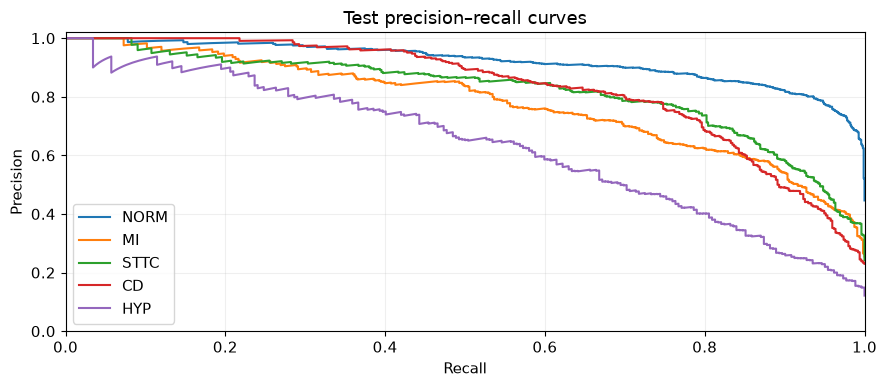

In [10]:
selected_tag = frozen["prespecified_explanation_checkpoint"]
selected_result = json.loads((RESULTS / "runs" / selected_tag / "test-results.json").read_text())
with np.load(RESULTS / "runs" / selected_tag / "test-predictions.npz", allow_pickle=False) as saved:
    y_selected, p_selected = saved["y_true"], saved["y_probability"]
    t_selected, selected_ids = saved["thresholds"], saved["ecg_id"]
print("Selected checkpoint:", selected_tag)
display(pd.DataFrame(selected_result["tuned_threshold_metrics"]["per_class"]).T[
    ["auroc", "average_precision", "sensitivity", "f1", "support"]])
fig, ax = plt.subplots()
for index, label in enumerate(CLASSES):
    precision, recall, _ = precision_recall_curve(y_selected[:, index], p_selected[:, index])
    ax.plot(recall, precision, label=label)
ax.set(xlabel="Recall", ylabel="Precision", title="Test precision–recall curves",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

HYP has fewer positive test examples and lower recall than NORM.
A strong overall AUROC can hide these category errors.

## 11. Separate thresholds from uncertainty

Thresholds change F1. They do not change AUROC because AUROC uses the continuous scores.
The bootstrap interval describes uncertainty for one checkpoint.
The standard deviation across seeds describes variation between training runs.

In [11]:
threshold_effect = pd.DataFrame({
    "Threshold 0.5": selected_result["fixed_threshold_metrics"],
    "Validation thresholds": selected_result["tuned_threshold_metrics"],
}).loc[["macro_auroc", "macro_f1", "micro_f1"]]
display(threshold_effect)
display(pd.Series(t_selected, index=CLASSES, name="Selected threshold").to_frame())
interval = selected_result["bootstrap"]["intervals"]["macro_auroc"]
print(f"Selected checkpoint AUROC: {selected_result['tuned_threshold_metrics']['macro_auroc']:.4f}")
print(f"95% patient-bootstrap interval: {interval[0]:.4f} to {interval[1]:.4f}")
print("The original interval uses 1,000 patient resamples. This cell reads the saved interval.")

,Threshold 0.5,Validation thresholds
macro_auroc,0.9178,0.9178
macro_f1,0.7199,0.736
micro_f1,0.7523,0.7704


,Selected threshold
NORM,0.61
MI,0.45
STTC,0.66
CD,0.59
HYP,0.69


Selected checkpoint AUROC: 0.9178
95% patient-bootstrap interval: 0.9099 to 0.9253
The original interval uses 1,000 patient resamples. This cell reads the saved interval.


## 12. Compare CPU inference time

The original timing uses one ECG per batch and four CPU threads.
Each checkpoint has 50 warm-up calls and 500 timed calls.
The table averages checkpoint medians across seeds.
It excludes file access, normalization, and explanation generation.

,Parameters,Median forward time (ms)
Model,,
compact_cnn,221573,0.6394
resnet1d,244005,0.8874
inception_time,115729,1.5735


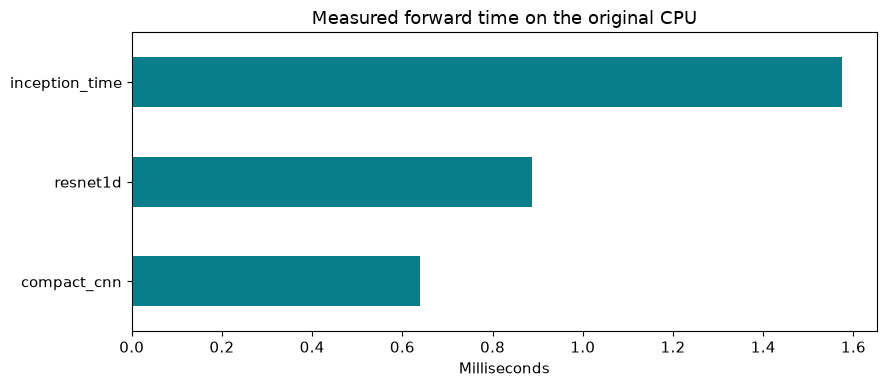

In [12]:
efficiency = pd.DataFrame([
    {"Model": name, "Parameters": aggregate[name]["parameters"],
     "Median forward time (ms)": aggregate[name]["metrics"]["latency_median_ms"]["mean"]}
    for name in config["models"]
]).set_index("Model")
display(efficiency)
efficiency["Median forward time (ms)"].plot.barh(color="#087E8B")
plt.xlabel("Milliseconds")
plt.ylabel("")
plt.title("Measured forward time on the original CPU")
plt.tight_layout()
plt.show()

## 13. Read the occlusion example

Occlusion replaces part of an ECG and measures the change in a category score.
The experiment uses 200 ms windows with a 100 ms stride.
It compares normalized zero with the median of each lead as replacement values.

ECG 162 is a prespecified MI true positive.
Its MI score is 0.860, above the threshold of 0.45.
The temporal responses have a Spearman correlation of 0.834 across the two replacement values.
This cell shows the saved figure. It does not repeat the occlusion calculation.

These responses describe model sensitivity. No clinician reviewed the highlighted regions.

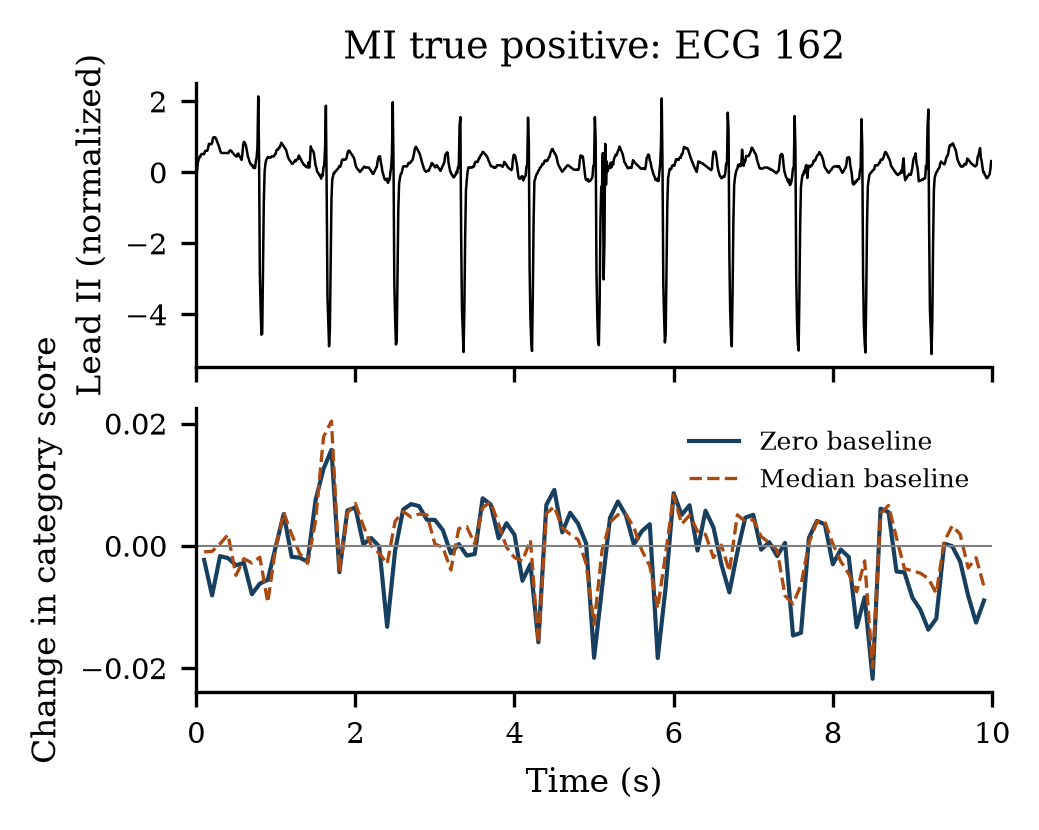

In [13]:
display(Image(filename=str(RESULTS / "figures/occlusion_MI_true_positive.png"), width=900))

## 14. Optional inference on a real ECG

To run a waveform through the saved model, set RUN_ECG_EXAMPLE to True.
This cell downloads one ECG and the release metadata when local files are absent.
It checks the files against the release checksums.
It then compares the new scores with the saved scores for that ECG.
The model and thresholds stay unchanged.

In [14]:
RUN_ECG_EXAMPLE = False
if RUN_ECG_EXAMPLE:
    import requests
    import wfdb
    base_url = "https://physionet-open.s3.amazonaws.com/ptb-xl/1.0.3/"
    sample_folder = ROOT / ".work/notebook-example"
    sample_folder.mkdir(parents=True, exist_ok=True)

    def sample_file(relative):
        local = ROOT / "data/raw/ptb-xl-1.0.3" / relative
        target = local if local.is_file() else sample_folder / relative
        if not target.is_file():
            response = requests.get(base_url + relative, timeout=60)
            response.raise_for_status()
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(response.content)
        return target

    checksum_lines = sample_file("SHA256SUMS.txt").read_text().splitlines()
    checksums = {name.lstrip("*").removeprefix("./"): value
                 for value, name in (line.split(maxsplit=1) for line in checksum_lines)}
    metadata_file = sample_file("ptbxl_database.csv")
    assert digest(metadata_file) == checksums["ptbxl_database.csv"]
    metadata = pd.read_csv(metadata_file).set_index("ecg_id")
    record_name = metadata.loc[162, "filename_lr"]
    paths = [sample_file(record_name + suffix) for suffix in [".hea", ".dat"]]
    for suffix, path in zip([".hea", ".dat"], paths):
        assert digest(path) == checksums[record_name + suffix]
    waveform, fields = wfdb.rdsamp(str(paths[0].with_suffix("")))
    assert waveform.shape == (1000, 12) and fields["fs"] == 100
    assert [name.upper() for name in fields["sig_name"]] == [name.upper() for name in leads]
    values = waveform.T.astype(np.float32)
    values = (values - train_mean[:, None]) / (train_std[:, None] + 1e-6)
    checkpoint = torch.load(RESULTS / "runs" / selected_tag / "best.pt",
                            map_location="cpu", weights_only=True)
    model = build_model(checkpoint["name"], config["dropout"], config["model_profile"])
    model.load_state_dict(checkpoint["model"])
    model.eval()
    with torch.inference_mode():
        scores = torch.sigmoid(model(torch.from_numpy(values[None]))).numpy()[0]
    saved_row = np.flatnonzero(selected_ids == 162).item()
    np.testing.assert_allclose(scores, p_selected[saved_row], rtol=1e-5, atol=1e-5)
    display(pd.DataFrame({"Category": CLASSES, "New score": scores,
                          "Saved score": p_selected[saved_row], "Threshold": t_selected,
                          "Predicted label": scores >= t_selected}))
    plt.plot(np.arange(1000) / 100, waveform[:, 1], color="#087E8B")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Lead II amplitude")
    plt.title("ECG 162")
    plt.tight_layout()
    plt.show()
else:
    print("ECG inference is off. Set RUN_ECG_EXAMPLE to True to run this section.")

ECG inference is off. Set RUN_ECG_EXAMPLE to True to run this section.


## 15. Optional fresh experiment

To repeat the full experiment, set RUN_FRESH_EXPERIMENT to True.
This cell creates a separate folder with the original source and configuration.
It downloads the dataset, prepares the cohort, trains all models, and evaluates the frozen checkpoints.
It then repeats the full evidence check and creates the analysis figures.
The original report results stay unchanged.

The original run used 32 GB RAM.
The full CPU experiment needs substantial memory, disk space, and time.
A Colab runtime can stop before it finishes.
GPU selection in Colab does not change this CPU protocol.
A new environment can produce different scores and timing measurements.

In [15]:
RUN_FRESH_EXPERIMENT = False
if RUN_FRESH_EXPERIMENT:
    fresh_root = ROOT / ".work/fresh-experiment"
    if fresh_root.exists():
        raise FileExistsError("The fresh experiment folder exists. Choose a new folder name.")
    fresh_root.mkdir(parents=True)
    for name in ["ecg_project", "configs", "scripts", "tests"]:
        shutil.copytree(ROOT / name, fresh_root / name,
                        ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
    shutil.copy2(ROOT / "requirements-lock.txt", fresh_root / "requirements-lock.txt")
    commands = [
        ["-m", "unittest", "discover", "-s", "tests", "-v"],
        ["-m", "ecg_project.data", "fetch", "--workers", "8"],
        ["-m", "ecg_project.data", "prepare"],
        ["-m", "ecg_project.experiment", "train"],
        ["-m", "ecg_project.experiment", "evaluate"],
        ["scripts/verify_evidence.py"],
        ["scripts/analyze_results.py"],
    ]
    for command in commands:
        print("Run:", " ".join(command), flush=True)
        subprocess.run([sys.executable, "-u", *command], cwd=fresh_root, check=True)
    print("The fresh results are in .work/fresh-experiment/results.")
else:
    print("Fresh training is off. The original experiment stays unchanged.")

Fresh training is off. The original experiment stays unchanged.


## 16. What the results support

The compact CNN provides a useful baseline for this internal test split.
Class weighting did not improve its average test scores.
HYP remains harder to detect than NORM.

This project uses one historical public dataset.
It does not include an external hospital test, a prospective study, or clinical review of the explanations.
Further work needs external testing, probability calibration, subgroup analysis, and expert review.

### Project files

- ecg_project/data.py: dataset download, label mapping, split checks, and normalization.
- ecg_project/models.py: the three neural architectures.
- ecg_project/experiment.py: training, checkpoint selection, thresholds, and evaluation.
- scripts/analyze_results.py: plots and occlusion analysis.
- report/Healthcare_ECG_IEEE_Report.docx: the six-page IEEE report.
- presentation/Healthcare_ECG_CA3_Presentation.pptx: the 14-slide presentation.

### Main sources

Wagner et al. PTB-XL dataset. Scientific Data, 2020.
[DOI](https://doi.org/10.1038/s41597-020-0495-6).

Strodthoff et al. Deep learning for ECG analysis. IEEE JBHI, 2021.
[DOI](https://doi.org/10.1109/JBHI.2020.3022989).

Strodthoff et al. PTB-XL+ feature dataset. Scientific Data, 2023.
[DOI](https://doi.org/10.1038/s41597-023-02153-8).

The IEEE report contains the complete reference list.